# Practice 13a — Fine-tuning with RF-DETR

**Goal:** teach a pretrained RF-DETR detector (`rfdetr`) a class it has never seen — `crack`, on concrete and asphalt surfaces.

| Question | Answer this notebook gives |
|:---|:---|
| What is fine-tuning for? | teaching a class the weights have never seen |
| How much data does it take? | a couple of hundred images, since the pretrained backbone is reused |
| What changes for masks instead of boxes? | the model class, and nothing else in the call |

- RF-DETR → a transformer-based detector; its 80 pretrained classes do not include yours
- GPU → needed (Colab: Runtime → Change runtime type → T4 GPU); the whole notebook takes about 40 minutes on a T4, 17 on the TITAN RTX behind the saved outputs

---
## Step 0. Setup

- `rfdetr[train]` → the models, the metrics and the training loop, which is built on PyTorch Lightning
- Lines starting with `[INFO]` or `[WARNING]`, and the notes Lightning prints → progress messages, not errors; a real error ends the cell with a traceback

In [1]:
import subprocess
import sys
from importlib.metadata import version

try:
    import rfdetr
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'rfdetr[train]'], check=True)
    import rfdetr

rfdetr_version = version('rfdetr')
print(f'rfdetr {rfdetr_version}')

W1116 21:28:51.639000 48952 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


rfdetr 1.12.1


In [2]:
import shutil
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import supervision as sv
from PIL import Image
from rfdetr import RFDETRNano, RFDETRSegNano

np.random.seed(42)
torch.manual_seed(42)

# downloads go to build/, the dataset to data/, the training runs to runs/rfdetr/
BUILD = Path('build')
DATA = Path('data')
RUNS = Path('runs') / 'rfdetr'
BUILD.mkdir(exist_ok=True)
DATA.mkdir(exist_ok=True)

print(f'GPU available : {torch.cuda.is_available()}')

GPU available : True


In [3]:
crack_dir = DATA / 'crack_full'

if not crack_dir.exists():
    urllib.request.urlretrieve(
        'https://github.com/ultralytics/assets/releases/download/v0.0.0/crack-seg.zip',
        BUILD / 'crack-seg.zip')
    # this archive has no top level folder inside, so the destination folder is named here
    with zipfile.ZipFile(BUILD / 'crack-seg.zip') as archive:
        archive.extractall(crack_dir)

for split in ['train', 'val', 'test']:
    images = sorted((crack_dir / 'images' / split).glob('*.jpg'))
    print(f'{split:5s} : {len(images)} images')

train : 3717 images
val   : 200 images
test  : 112 images


---
## Step 1. What the Pretrained Models Do Here

- `RFDETRNano` (boxes) and `RFDETRSegNano` (masks, one pixel region per object) → the COCO weights, untouched
- `threshold=0.25` → detections below 25% confidence are dropped
- `predict` returns a `Detections` object of the `supervision` library → its annotators draw the boxes, masks and class names

In [4]:
model_pretrained = RFDETRNano()
model_pretrained_seg = RFDETRSegNano()

crack_in_coco = 'crack' in model_pretrained.class_names
print(f"'crack' among the 80 class names : {crack_in_coco}")
print()

crack_images = sorted((crack_dir / 'images' / 'test').glob('*.jpg'))[:4]
for image_path in crack_images:
    image = Image.open(image_path).convert('RGB')
    detections = model_pretrained.predict(image, threshold=0.25)
    detections_seg = model_pretrained_seg.predict(image, threshold=0.25)
    print(f'{image_path.name[:12]} : detection {len(detections)} objects, '
          f'segmentation {len(detections_seg)} objects')

[2026-11-16 21:28:53] [INFO] rf-detr - File C:\Users\User\.roboflow\models\rf-detr-nano.pth already exists with correct MD5 hash.


[2026-11-16 21:28:54] [INFO] rf-detr - File C:\Users\User\.roboflow\models\rf-detr-nano.pth already exists with correct MD5 hash.


[2026-11-16 21:28:55] [INFO] rf-detr - File C:\Users\User\.roboflow\models\rf-detr-seg-nano.pt already exists with correct MD5 hash.


[2026-11-16 21:28:55] [INFO] rf-detr - File C:\Users\User\.roboflow\models\rf-detr-seg-nano.pt already exists with correct MD5 hash.


[2026-11-16 21:28:56] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. Create predictor = native_model.inference(...) and use predictor.predict(...). For a checkpoint, first load native_model = RFDETR.from_checkpoint(...).


'crack' among the 80 class names : False



[2026-11-16 21:28:56] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. Create predictor = native_model.inference(...) and use predictor.predict(...). For a checkpoint, first load native_model = RFDETR.from_checkpoint(...).


1616.rf.c868 : detection 0 objects, segmentation 0 objects
1675.rf.e3aa : detection 1 objects, segmentation 0 objects
1686.rf.809f : detection 0 objects, segmentation 0 objects
1706.rf.011d : detection 0 objects, segmentation 0 objects


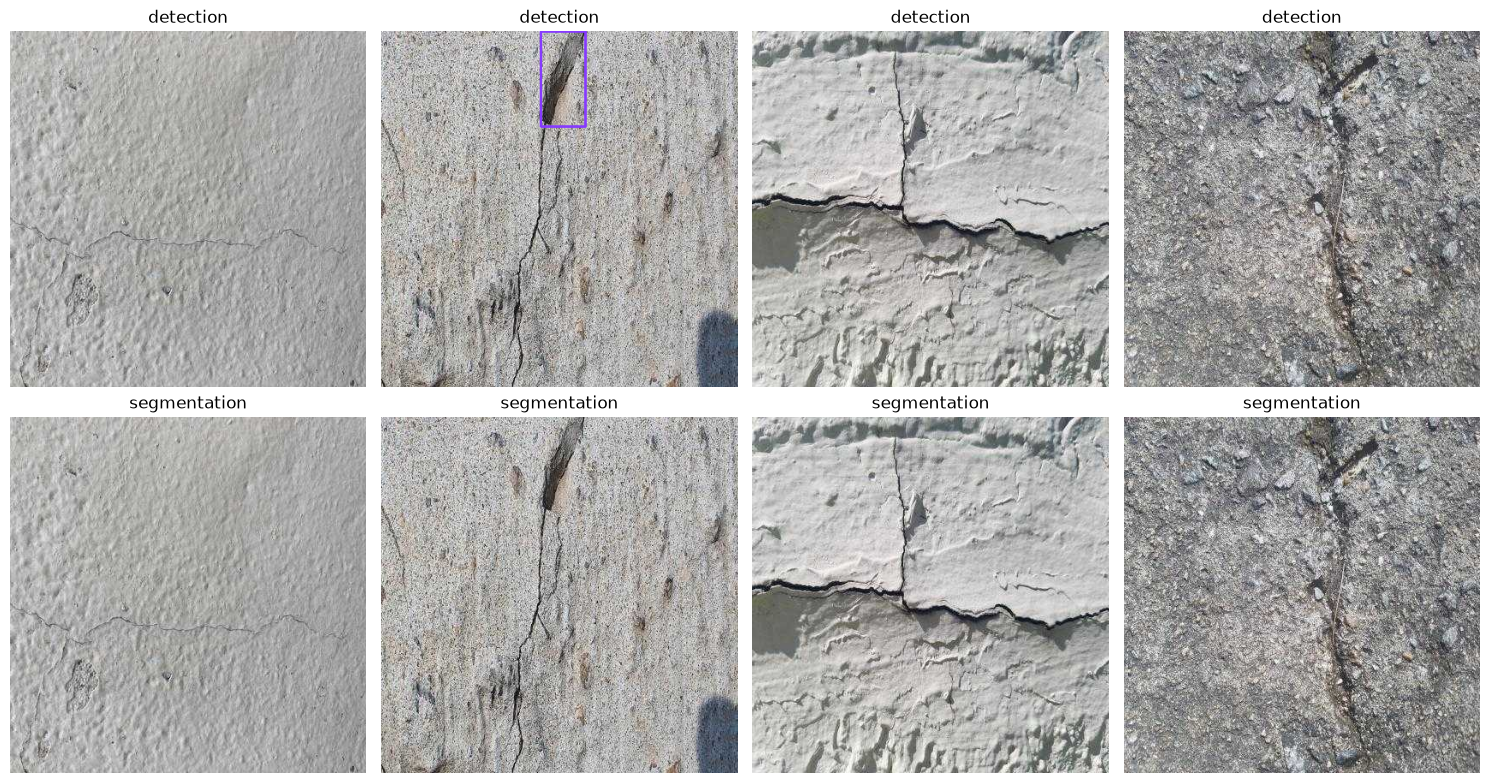

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(15, 8))

for column, image_path in enumerate(crack_images):
    image = Image.open(image_path).convert('RGB')
    detections = model_pretrained.predict(image, threshold=0.25)
    detections_seg = model_pretrained_seg.predict(image, threshold=0.25)

    annotated = sv.BoxAnnotator().annotate(image.copy(), detections)
    annotated = sv.LabelAnnotator().annotate(annotated, detections)
    axes[0, column].imshow(annotated)
    axes[0, column].set_title('detection')
    axes[0, column].axis('off')

    annotated_seg = sv.MaskAnnotator().annotate(image.copy(), detections_seg)
    annotated_seg = sv.LabelAnnotator().annotate(annotated_seg, detections_seg)
    axes[1, column].imshow(annotated_seg)
    axes[1, column].set_title('segmentation')
    axes[1, column].axis('off')

plt.tight_layout()
plt.show()

- Almost nothing is drawn: one box on the second image, which the model calls `bird`, and no mask anywhere; yet the weights are not broken
- The output layer is fixed at training time → 80 class names (the logs count 90, COCO's id numbers with gaps), none of them `crack`

---
## Step 2. The Label Format

- `images/` and `labels/` mirror each other → one label file of the same name per image

| Label | One line | Length |
|:---|:---|:---|
| Segmentation | `class x1 y1 x2 y2 ... xn yn`, an outline | varies |
| Detection | `class cx cy w h` | fixed |

- One line per object, coordinates divided by the image size; the next cell prints one file's lines

In [6]:
image_path = crack_images[0]
label_path = crack_dir / 'labels' / 'test' / (image_path.stem + '.txt')
label_lines = label_path.read_text().strip().splitlines()

print(np.shape(label_lines))
label_lines

(3,)


['0 0.03686995913461539 0.9808467740384615 0.03245967788461539 0.9595654110576923 0.030569555288461538 0.9517249110576922 0.03497983894230769 0.9438844086538462 0.0375 0.9304435480769231 0.038130040865384615 0.9203629038461538 0.053251007211538456 0.9091621875 0.057031250000000006 0.9002016129807693 0.05955141105769231 0.8822804663461539 0.060181451923076924 0.8699596778846155 0.06585181490384616 0.85987903125 0.07089213701923078 0.8520385312500001 0.07341229807692308 0.8408378125 0.07341229807692308 0.8307571682692309 0.07782258173076924 0.8195564519230769 0.0765625 0.8128360216346154 0.08034274278846154 0.7926747307692307 0.08790322596153846 0.7769937283653847 0.09294354807692308 0.7691532259615385 0.09420362980769231 0.753472221153846 0.10050403125 0.7310707884615385 0.11499495913461538 0.7153897860576923 0.12444556490384615 0.7086693557692307 0.13641633173076922 0.6974686370192308 0.14523689423076924 0.6851478485576923 0.15090725721153847 0.6717069903846155 0.15342741826923076 0.65

In [7]:
values = label_lines[0].split()
print(values)
class_id = values[0]
coordinates = values[1:]
n_points = len(coordinates) // 2
print(f'class          : {class_id}')
print(f'coordinates    : {len(coordinates)}')
print(f'outline points : {n_points}')

['0', '0.03686995913461539', '0.9808467740384615', '0.03245967788461539', '0.9595654110576923', '0.030569555288461538', '0.9517249110576922', '0.03497983894230769', '0.9438844086538462', '0.0375', '0.9304435480769231', '0.038130040865384615', '0.9203629038461538', '0.053251007211538456', '0.9091621875', '0.057031250000000006', '0.9002016129807693', '0.05955141105769231', '0.8822804663461539', '0.060181451923076924', '0.8699596778846155', '0.06585181490384616', '0.85987903125', '0.07089213701923078', '0.8520385312500001', '0.07341229807692308', '0.8408378125', '0.07341229807692308', '0.8307571682692309', '0.07782258173076924', '0.8195564519230769', '0.0765625', '0.8128360216346154', '0.08034274278846154', '0.7926747307692307', '0.08790322596153846', '0.7769937283653847', '0.09294354807692308', '0.7691532259615385', '0.09420362980769231', '0.753472221153846', '0.10050403125', '0.7310707884615385', '0.11499495913461538', '0.7153897860576923', '0.12444556490384615', '0.7086693557692307', '

- `class x1 y1 x2 y2 ...` → the first number is the class, the rest are (x, y) pairs along the outline
- 87 points trace one crack; a detection model reads the same line as the outline's bounding box → one dataset trains both kinds of model

---
## Step 3. Pointing RF-DETR at the Data

- RF-DETR Nano → 30.5 M parameters with its COCO output layer (the segmentation model 33.6 M); YOLO11n, a detector often used for this task, has 2.6 M → every training step is far heavier
- So this example trains on a part of the data → `fraction = 0.05`, the first 186 of the 3,717 training images
- The library reads a whole folder → those 186 images and their label files are copied to `train_small`

In [8]:
fraction = 0.05

train_images = sorted((crack_dir / 'images' / 'train').glob('*.jpg'))
n_train = round(fraction * len(train_images))

small_image_dir = crack_dir / 'images' / 'train_small'
small_label_dir = crack_dir / 'labels' / 'train_small'
for folder in [small_image_dir, small_label_dir]:
    shutil.rmtree(folder, ignore_errors=True)
    folder.mkdir()

for image_path in train_images[:n_train]:
    label_path = crack_dir / 'labels' / 'train' / (image_path.stem + '.txt')
    shutil.copy(image_path, small_image_dir)
    shutil.copy(label_path, small_label_dir)

print(f'training images          : {len(train_images)}')
print(f'copied to train_small    : {n_train}')

training images          : 3717
copied to train_small    : 186


### The `data.yaml` File

- `data.yaml` → where the folders are, what the class indices mean; it sits inside the dataset folder, paths relative to it
- Labels → found by swapping `images` for `labels` in each path
- `test` → used neither for training nor for picking the best epoch, so it is the split reported below

In [9]:
crack_yaml_path = crack_dir / 'data.yaml'

with open(crack_yaml_path, 'w', encoding='utf-8') as yaml_file:
    yaml_file.write('train: images/train_small\n')
    yaml_file.write('val: images/val\n')
    yaml_file.write('test: images/test\n')
    yaml_file.write('names:\n')
    yaml_file.write('  0: crack\n')

print(crack_yaml_path.read_text().strip())

train: images/train_small
val: images/val
test: images/test
names:
  0: crack


### Scoring the Pretrained Model

- `evaluate(dataset_dir=..., split='test')` → box mAP@50 on the test split of the folder that holds `data.yaml`; a predicted box counts when its IoU with a label is at least 0.5 and its class matches
- `Test metric` table → every score of the evaluation; `test/mAP_50` is box mAP@50
- This is run A of the comparison in Step 5

In [10]:
metrics_pretrained = model_pretrained.evaluate(dataset_dir=str(crack_dir), split='test')
map50_test_pretrained = metrics_pretrained['test/mAP_50']

print(f'pretrained box mAP@50 : {map50_test_pretrained:.5f}')

W1116 21:28:59.367000 48952 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


[2026-11-16 21:29:00] [INFO] rf-detr - Using multi-scale training with square resize and scales: [544]


C:\Users\User\AppData\Local\Temp\ipykernel_48952\3445077086.py:1: UserWarning: Dataset 'D:\Main\00_Research\00_Python\00_Lecture\03_Advanced_AI-ME_Graduate\data\crack_full' has 1 classes but the model has num_classes=90. Evaluating with the model's head unchanged; class indices may not line up with the dataset.
  metrics_pretrained = model_pretrained.evaluate(dataset_dir=str(crack_dir), split='test')
Using 16bit Automatic Mixed Precision (AMP)


creating index...
index created!


GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


... (3 outputs left out)

D:\Main\00_Research\00_Python\00_Lecture\03_Advanced_AI-ME_Graduate\build\venv_rfdetr\Lib\site-packages\rfdetr\models\_assignment.py:76: RuntimeWarning: Triton linear-assignment support is unavailable for this CUDA input; using SciPy on CPU.
  assignment = torch_linear_assignment.batch_linear_assignment(stacked)


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          test/F1          │            0.0            │
│         test/loss         │     7.473114967346191     │
│        test/mAP_50        │            0.0            │
│      test/mAP_50_95       │            0.0            │
│        test/mAP_75        │            0.0            │
│         test/mAR          │            0.0            │
│      test/precision       │            0.0            │
│        test/recall        │            0.0            │
└───────────────────────────┴───────────────────────────┘

pretrained box mAP@50 : 0.00000


- Exactly 0 → the labels say `crack`, the model answers in COCO class names, so no prediction counts; the floor to beat

### Labels Next to the Pretrained Predictions

- `sv.DetectionDataset.from_yolo` → reads the label files; `annotations[path]` gives one image's labels as a `Detections` object
- `threshold=0.05` → even the weakest guesses of the pretrained model are drawn, with the class names it gives them

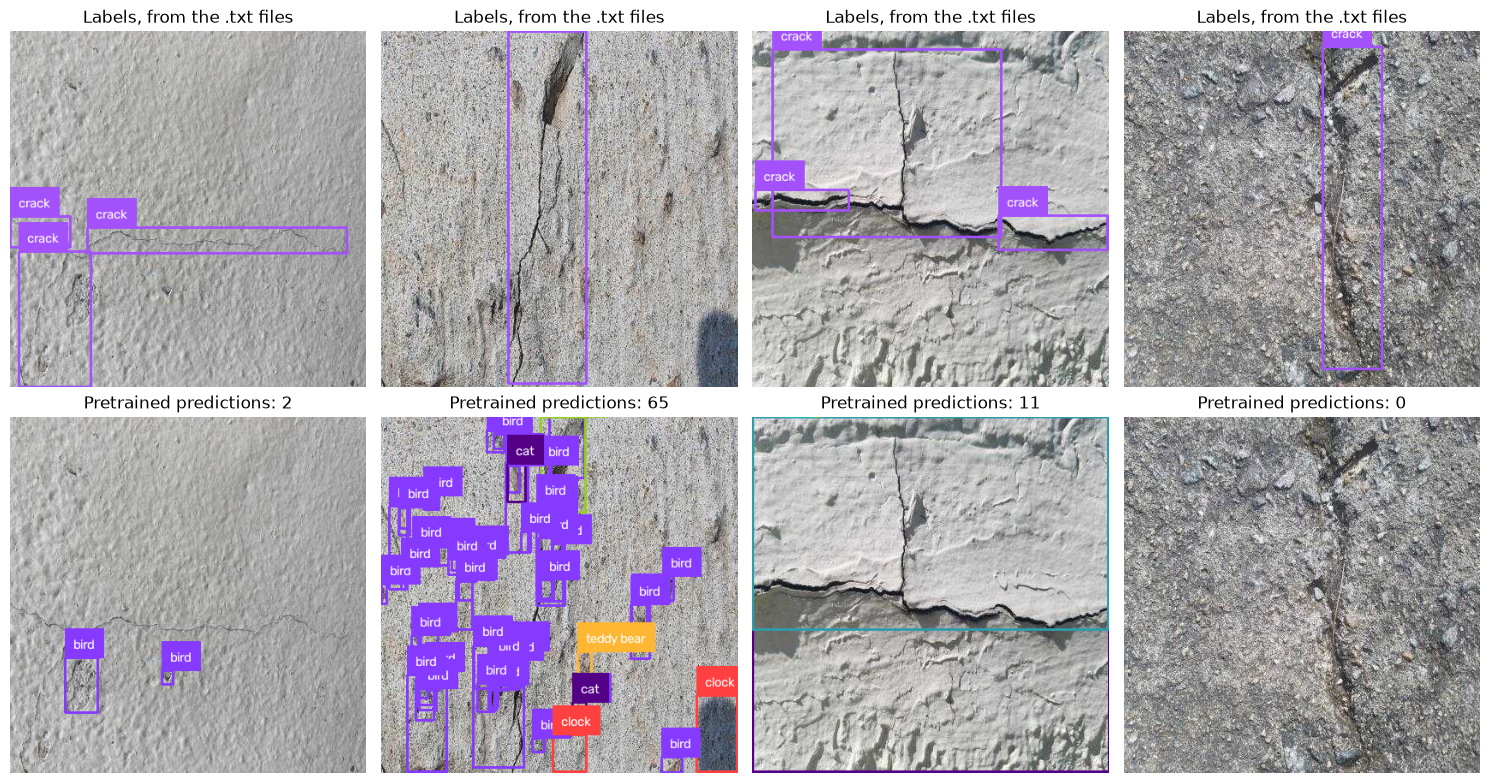

In [11]:
labels = sv.DetectionDataset.from_yolo(
    images_directory_path=str(crack_dir / 'images' / 'test'),
    annotations_directory_path=str(crack_dir / 'labels' / 'test'),
    data_yaml_path=str(crack_yaml_path))

fig, axes = plt.subplots(2, 4, figsize=(15, 8))

for column, image_path in enumerate(crack_images):
    image = Image.open(image_path).convert('RGB')
    detections_label = labels.annotations[str(image_path)]
    detections = model_pretrained.predict(image, threshold=0.05)

    annotated_label = sv.BoxAnnotator().annotate(image.copy(), detections_label)
    annotated_label = sv.LabelAnnotator().annotate(annotated_label, detections_label)
    axes[0, column].imshow(annotated_label)
    axes[0, column].set_title('Labels, from the .txt files')
    axes[0, column].axis('off')

    annotated = sv.BoxAnnotator().annotate(image.copy(), detections)
    annotated = sv.LabelAnnotator().annotate(annotated, detections)
    axes[1, column].imshow(annotated)
    axes[1, column].set_title(f'Pretrained predictions: {len(detections)}')
    axes[1, column].axis('off')

plt.tight_layout()
plt.show()

- Top: the label boxes, class `crack`; bottom: the pretrained model's weak guesses at the same images carry COCO names, mostly `bird`
- 2, 65, 11 and 0 guesses → none of them is a crack to this model

---
## Step 4. Fine-tuning a Detector

| Argument | Effect |
|:---|:---|
| `dataset_dir` | the folder that holds `data.yaml` |
| `batch_size=4`, `lr=1e-4` | the library defaults, written out |
| `compute_val_loss=True` | validation loss logged every epoch too |
| `output_dir` | run folder `runs/rfdetr/crack_detect` |

- `train()` rebuilds the output layer for the one class; every other layer keeps training from the COCO weights
- `Best EMA metric improved to ...` → mAP@50:95 on `val` whenever an epoch beats the best so far; EMA, a moving average of the weights, is what gets scored
- `evaluate(split='test')` then scores the trained model → run B

In [12]:
epochs = 20

model_finetuned = RFDETRNano()
model_finetuned.train(dataset_dir=str(crack_dir), epochs=epochs, batch_size=4, lr=1e-4,
                      seed=42, compute_val_loss=True, output_dir=str(RUNS / 'crack_detect'))

metrics_finetuned = model_finetuned.evaluate(dataset_dir=str(crack_dir), split='test')
map50_test_finetuned = metrics_finetuned['test/mAP_50']

print(f'fine-tuned box mAP@50 : {map50_test_finetuned:.5f}')

[2026-11-16 21:29:13] [INFO] rf-detr - File C:\Users\User\.roboflow\models\rf-detr-nano.pth already exists with correct MD5 hash.


[2026-11-16 21:29:14] [INFO] rf-detr - File C:\Users\User\.roboflow\models\rf-detr-nano.pth already exists with correct MD5 hash.


[2026-11-16 21:29:15] [INFO] rf-detr - File C:\Users\User\.roboflow\models\rf-detr-nano.pth already exists with correct MD5 hash.


[2026-11-16 21:29:16] [WARNING] rf-detr - Checkpoint has 90 classes but model is configured for 1. The detection head will be re-initialized to 1 classes.


[2026-11-16 21:29:16] [WARNING] rf-detr - TensorBoard logging disabled: No module named 'tensorboard'. If using NumPy 2.x, ensure your TensorBoard installation is NumPy 2.0 compatible (the failure can originate from tensorboard.compat.tensorflow_stub). Install TensorBoard with: pip install tensorboard


Using 16bit Automatic Mixed Precision (AMP)


... (34 outputs left out)

D:\Main\00_Research\00_Python\00_Lecture\03_Advanced_AI-ME_Graduate\build\venv_rfdetr\Lib\site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          test/F1          │    0.7108014225959778     │
│         test/loss         │     4.919504642486572     │
│        test/mAP_50        │    0.6726244688034058     │
│      test/mAP_50_95       │    0.4615015387535095     │
│        test/mAP_75        │    0.4966018795967102     │
│         test/mAR          │    0.7472972869873047     │
│      test/precision       │    0.7338129281997681     │
│        test/recall        │    0.6891891956329346     │
└───────────────────────────┴───────────────────────────┘

fine-tuned box mAP@50 : 0.67262


- 0.00 → 0.67 on the test split, from 186 images and 20 epochs
- A rerun with the same settings moves the score by a few hundredths, even with the seed
- `Trainer.fit stopped: max_epochs=20 reached` and `regular=0.0000` in the log → the normal end of a run; only the EMA weights are scored

### The Training History

- Every epoch is logged to `metrics.csv` in the run folder → one row for the training loss, another for the `val` scores
- `dropna` → keeps the rows that hold the named column

    epoch  val/loss  val/mAP_50
0       0  5.675187    0.450094
3       1  5.272843    0.648801
6       2  5.170085    0.719463
9       3  5.451907    0.704734
12      4  4.997716    0.755100


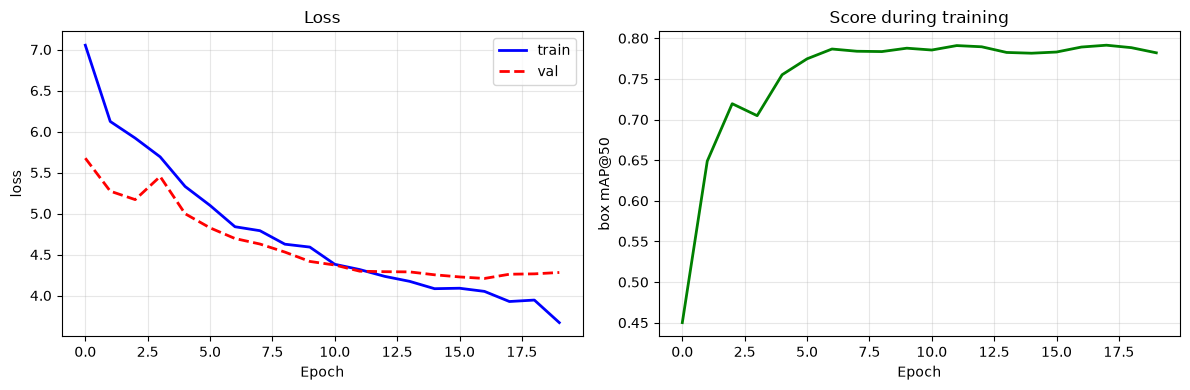

In [13]:
history_finetuned = pd.read_csv(RUNS / 'crack_detect' / 'metrics.csv')
train_rows = history_finetuned.dropna(subset=['train/loss'])
val_rows = history_finetuned.dropna(subset=['val/loss'])
print(val_rows[['epoch', 'val/loss', 'val/mAP_50']].head())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(train_rows['epoch'], train_rows['train/loss'], 'b-', linewidth=2, label='train')
axes[0].plot(val_rows['epoch'], val_rows['val/loss'], 'r--', linewidth=2, label='val')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('loss')
axes[0].set_title('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(val_rows['epoch'], val_rows['val/mAP_50'], 'g-', linewidth=2)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('box mAP@50')
axes[1].set_title('Score during training')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Training loss falls through the run, 7.1 to 3.7; validation loss settles near 4.2 around epoch 14
- Right: box mAP@50 on the `val` split after every epoch → 0.45 after the first epoch, about 0.79 from the seventh on; the 0.67 above is the `test` split

### The Fine-tuned Detector on the Four Test Images

[2026-11-16 21:34:58] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. Create predictor = native_model.inference(...) and use predictor.predict(...). For a checkpoint, first load native_model = RFDETR.from_checkpoint(...).


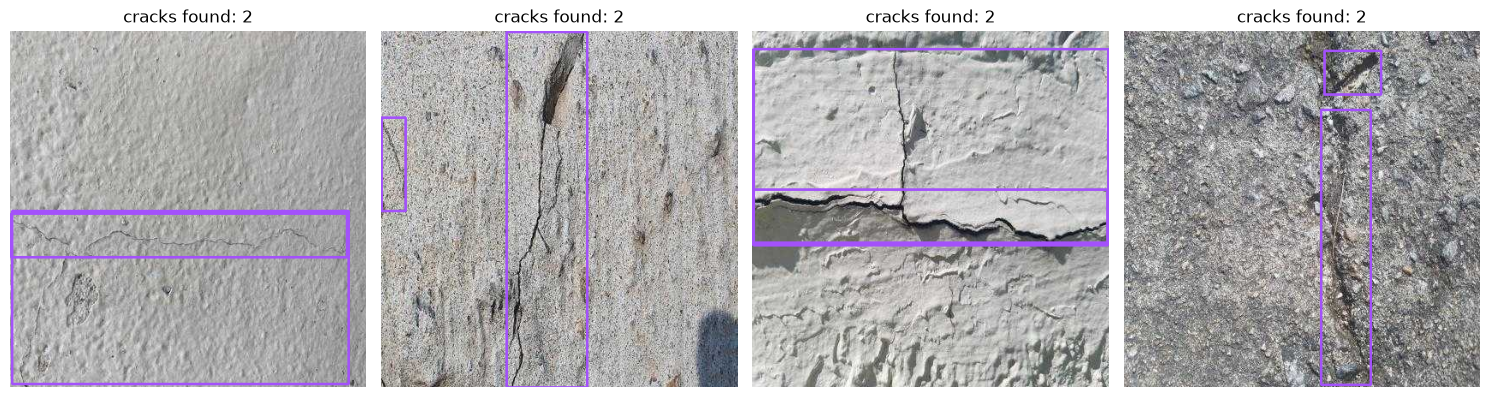

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

for panel_axis, image_path in zip(axes, crack_images):
    image = Image.open(image_path).convert('RGB')
    detections = model_finetuned.predict(image, threshold=0.25)
    annotated = sv.BoxAnnotator().annotate(image.copy(), detections)
    panel_axis.imshow(annotated)
    panel_axis.set_title(f'cracks found: {len(detections)}')
    panel_axis.axis('off')

plt.tight_layout()
plt.show()

- Every image gets boxes at `threshold=0.25`; a box that spans the frame is not a mistake → the crack runs across it

---
## Step 5. Why the Pretrained Weights Matter

| Item | A: pretrained | B: fine-tuned | C: from scratch |
|:---|:---|:---|:---|
| **initial weights** | **COCO** | **COCO** | **random** |
| **training** | **none** | **20 epochs** | **20 epochs** |
| `batch_size`, `lr`, `seed` | · | same | same |
| data, test split | same | same | same |

- A vs B → the training; B vs C → the starting weights
- `RFDETRNano(pretrain_weights=None)` → the same architecture with random weights, the backbone included; `RFDETRNano()` is that architecture plus the COCO weights

In [15]:
model_scratch = RFDETRNano(pretrain_weights=None)
model_scratch.train(dataset_dir=str(crack_dir), epochs=epochs, batch_size=4, lr=1e-4,
                    seed=42, compute_val_loss=True, output_dir=str(RUNS / 'crack_scratch'))

metrics_scratch = model_scratch.evaluate(dataset_dir=str(crack_dir), split='test')
map50_test_scratch = metrics_scratch['test/mAP_50']

print(f'from-scratch box mAP@50 : {map50_test_scratch:.5f}')

D:\Main\00_Research\00_Python\00_Lecture\03_Advanced_AI-ME_Graduate\build\venv_rfdetr\Lib\site-packages\pydantic\main.py:280: PretrainWeightsCompatibilityWarning: RFDETRNanoConfig was instantiated with pretrain_weights=None. The model will be initialised from scratch, which typically produces lower accuracy than fine-tuning from the published checkpoint ('rf-detr-nano.pth').
  validated_self = self.__pydantic_validator__.validate_python(data, self_instance=self)
[2026-11-16 21:34:58] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights and the backbone starts from random initialization. Load pretrained RF-DETR weights or a checkpoint to initialize it.


[2026-11-16 21:34:58] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights and the backbone starts from random initialization. Load pretrained RF-DETR weights or a checkpoint to initialize it.


D:\Main\00_Research\00_Python\00_Lecture\03_Advanced_AI-ME_Graduate\build\venv_rfdetr\Lib\site-packages\pydantic\main.py:129: PretrainWeightsCompatibilityWarning: RFDETRNanoConfig was instantiated with pretrain_weights=None. The model will be initialised from scratch, which typically produces lower accuracy than fine-tuning from the published checkpoint ('rf-detr-nano.pth').
  'validate_assignment': lambda model, name, val: model.__pydantic_validator__.validate_assignment(model, name, val),  # pyright: ignore[reportAssignmentType]


[2026-11-16 21:34:58] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights and the backbone starts from random initialization. Load pretrained RF-DETR weights or a checkpoint to initialize it.


[2026-11-16 21:34:58] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights and the backbone starts from random initialization. Load pretrained RF-DETR weights or a checkpoint to initialize it.


[2026-11-16 21:34:59] [WARNING] rf-detr - TensorBoard logging disabled: No module named 'tensorboard'. If using NumPy 2.x, ensure your TensorBoard installation is NumPy 2.0 compatible (the failure can originate from tensorboard.compat.tensorflow_stub). Install TensorBoard with: pip install tensorboard


... (35 outputs left out)

D:\Main\00_Research\00_Python\00_Lecture\03_Advanced_AI-ME_Graduate\build\venv_rfdetr\Lib\site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          test/F1          │    0.21153846383094788    │
│         test/loss         │     8.848013877868652     │
│        test/mAP_50        │    0.09600655734539032    │
│      test/mAP_50_95       │   0.023808564990758896    │
│        test/mAP_75        │   0.003465294139459729    │
│         test/mAR          │    0.3121621608734131     │
│      test/precision       │    0.16417910158634186    │
│        test/recall        │    0.29729729890823364    │
└───────────────────────────┴───────────────────────────┘

from-scratch box mAP@50 : 0.09601


In [16]:
print('                  box mAP@50')
print(f'A pretrained     {map50_test_pretrained:11.5f}')
print(f'B fine-tuned     {map50_test_finetuned:11.5f}')
print(f'C from scratch   {map50_test_scratch:11.5f}')

                  box mAP@50
A pretrained         0.00000
B fine-tuned         0.67262
C from scratch       0.09601


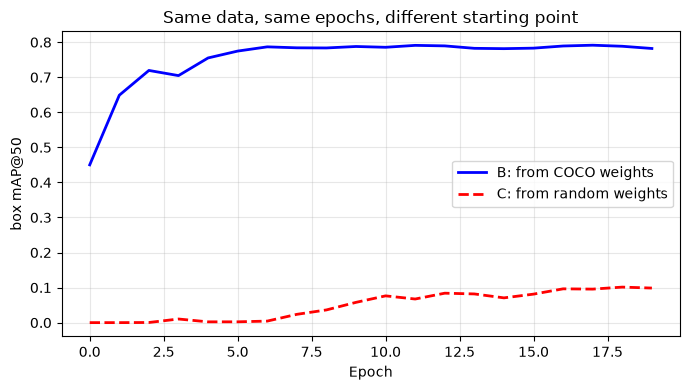

In [17]:
history_scratch = pd.read_csv(RUNS / 'crack_scratch' / 'metrics.csv')
val_rows_scratch = history_scratch.dropna(subset=['val/loss'])

plt.figure(figsize=(7, 4))
plt.plot(val_rows['epoch'], val_rows['val/mAP_50'], 'b-',
         linewidth=2, label='B: from COCO weights')
plt.plot(val_rows_scratch['epoch'], val_rows_scratch['val/mAP_50'], 'r--',
         linewidth=2, label='C: from random weights')
plt.xlabel('Epoch')
plt.ylabel('box mAP@50')
plt.title('Same data, same epochs, different starting point')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- C stays near zero, 0.01 at most, through epoch 6 and ends at 0.10 on the test split, against B's 0.67 → same images, epochs and learning rate, but no backbone that already knows edges and textures
- A couple of hundred images can name a new class, not teach vision from nothing

---
## Step 6. The Same Training, With Masks

- `RFDETRSegNano` replaces `RFDETRNano` → nothing else in the call changes
- Same dataset → its labels were outlines all along
- Evaluation now reports two scores → `test/mAP_50` for boxes, `test/segm_mAP_50` for masks

In [18]:
model_seg = RFDETRSegNano()
model_seg.train(dataset_dir=str(crack_dir), epochs=epochs, batch_size=4, lr=1e-4,
                seed=42, compute_val_loss=True, output_dir=str(RUNS / 'crack_segment'))

metrics_seg = model_seg.evaluate(dataset_dir=str(crack_dir), split='test')
map50_test_seg = metrics_seg['test/mAP_50']
mask_map50_test_seg = metrics_seg['test/segm_mAP_50']

print(f'box  mAP@50 : {map50_test_seg:.5f}')
print(f'mask mAP@50 : {mask_map50_test_seg:.5f}')

[2026-11-16 21:39:35] [INFO] rf-detr - File C:\Users\User\.roboflow\models\rf-detr-seg-nano.pt already exists with correct MD5 hash.


[2026-11-16 21:39:35] [INFO] rf-detr - File C:\Users\User\.roboflow\models\rf-detr-seg-nano.pt already exists with correct MD5 hash.


[2026-11-16 21:39:36] [INFO] rf-detr - File C:\Users\User\.roboflow\models\rf-detr-seg-nano.pt already exists with correct MD5 hash.


[2026-11-16 21:39:36] [WARNING] rf-detr - Checkpoint has 90 classes but model is configured for 1. The detection head will be re-initialized to 1 classes.


[2026-11-16 21:39:36] [WARNING] rf-detr - TensorBoard logging disabled: No module named 'tensorboard'. If using NumPy 2.x, ensure your TensorBoard installation is NumPy 2.0 compatible (the failure can originate from tensorboard.compat.tensorflow_stub). Install TensorBoard with: pip install tensorboard


Using 16bit Automatic Mixed Precision (AMP)


... (28 outputs left out)

D:\Main\00_Research\00_Python\00_Lecture\03_Advanced_AI-ME_Graduate\build\venv_rfdetr\Lib\site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          test/F1          │    0.5692307949066162     │
│         test/loss         │    20.048044204711914     │
│        test/mAP_50        │    0.6765173077583313     │
│      test/mAP_50_95       │    0.47713643312454224    │
│        test/mAP_75        │    0.5126033425331116     │
│         test/mAR          │    0.7310810685157776     │
│      test/precision       │    0.6607142686843872     │
│        test/recall        │            0.5            │
│     test/segm_mAP_50      │    0.3936973810195923     │
│    test/segm_mAP_50_95    │    0.09893946349620819    │
└───────────────────────────┴───────────────────────────┘

box  mAP@50 : 0.67652
mask mAP@50 : 0.39370


- Box mAP@50 0.68 → close to the detector's 0.67; mask mAP@50 0.39
- Mask mAP@50 is lower → the IoU is now computed on mask pixels instead of box corners, and an outline must be right pixel by pixel
- `Best EMA metric` in this log → mask mAP@50:95; its last improvement is at epoch 3, and later epochs stay close to it

### The Segmentation Model on the Same Four Images

[2026-11-16 21:45:41] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. Create predictor = native_model.inference(...) and use predictor.predict(...). For a checkpoint, first load native_model = RFDETR.from_checkpoint(...).


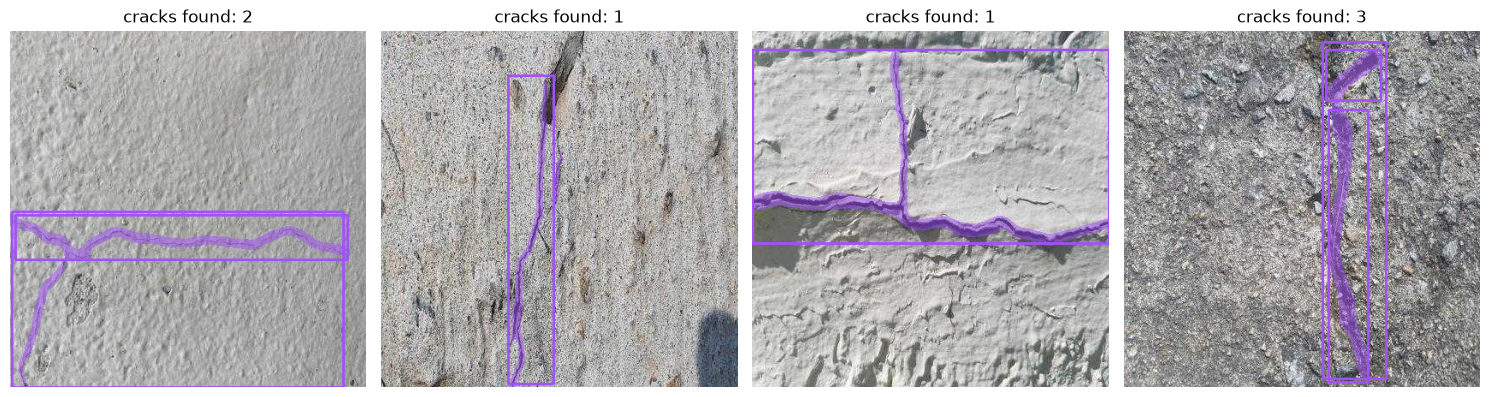

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

for panel_axis, image_path in zip(axes, crack_images):
    image = Image.open(image_path).convert('RGB')
    detections_seg = model_seg.predict(image, threshold=0.25)
    annotated_seg = sv.MaskAnnotator().annotate(image.copy(), detections_seg)
    annotated_seg = sv.BoxAnnotator().annotate(annotated_seg, detections_seg)
    panel_axis.imshow(annotated_seg)
    panel_axis.set_title(f'cracks found: {len(detections_seg)}')
    panel_axis.axis('off')

plt.tight_layout()
plt.show()

- Masks follow the crack inside each box; every image gets at least one, the fourth three that overlap

### Instance and Semantic Segmentation

- **Instance** segmentation → one mask per object, and the count is part of the answer

| Task | One output covers |
|:---|:---|
| Semantic segmentation | every pixel of a class, as a single region |
| Instance segmentation | every pixel of one object, one mask per object |

- For cracks the two are close → a branching crack is one connected shape; the labels decide where an instance ends

---
## Step 7. Why a Mask and Not a Box

- A crack is thin and winding → it covers little of its own box
- `detections.area` → the pixel count of each mask; `detections.box_area` → the area of each box

In [20]:
print('image          mask pixels   box pixels   fill')
for image_path in crack_images:
    image = Image.open(image_path).convert('RGB')
    detections_seg = model_seg.predict(image, threshold=0.25)
    for index in range(len(detections_seg)):
        mask_pixels = detections_seg.area[index]
        box_pixels = detections_seg.box_area[index]
        fill = mask_pixels / box_pixels
        print(f'{image_path.name[:12]} {mask_pixels:12.0f} {box_pixels:12.0f}   {fill:.3f}')

image          mask pixels   box pixels   fill
1616.rf.c868         6213        79311   0.078
1616.rf.c868         4138        20117   0.206
1675.rf.e3aa         3055        19232   0.159
1686.rf.809f         8025        93767   0.086
1706.rf.011d         6396        28987   0.221
1706.rf.011d         4221        14631   0.289
1706.rf.011d         1482         3781   0.392


- Fill 0.08–0.39 → most of each box is surface, not crack
- Damage measures such as area or length → read them from the mask

---
## Summary

| Run | Starts from | Box mAP@50, test split |
|:---|:---|:---|
| A: pretrained | COCO weights, no training | 0.000 |
| B: fine-tuned | COCO weights, 20 epochs | 0.673 |
| C: from scratch | random weights, 20 epochs | 0.096 |

- Fine-tuning → teaches the weights a class they could not name before
- Swapping the model class → the same call trains a segmentation model; a crack fills only part of its box

---
## A Note on the License

- `rfdetr`, its detection models Nano to Large and its segmentation models → Apache 2.0; use inside a commercial or closed-source product is allowed, with the license and copyright notices kept
- For comparison, `ultralytics` (YOLO) → AGPL-3.0; a closed-source product needs its Enterprise License

---
## Exercises

1. `fraction = 0.02`, rerun Step 3 and Step 4, then set it back to 0.05 — how much of B's score survives on about 74 images instead of 186?
2. `epochs = 5` in Step 4, rerun Steps 4 to 6 — all three training calls read that variable; how much of B's score survives?
3. Predict with `model_seg` and `threshold=0.05` on the four test images — which extra cracks appear?

In [21]:
# Write your code here